# 04 - REV and heterogeneity of the pores and grains (Task 2 and Challenge C1)

Is the pore/grain arrangement **homogeneous** at the scale of the thin section, and how large must a sample be to
represent it? We use six complementary tools:

| # | Tool | Question it answers | Reference |
|---|---|---|---|
| 1 | **REV** by random windows | How big must a window be for a stable porosity? | Bear (1972) |
| 2 | **Two-point correlation / indicator variogram** | Over what distance are pores correlated? Is there anisotropy? | Torquato (2002) |
| 3 | **Integral range** | Does the REV follow from the correlation length (theory vs data)? | Lantuejoul (1991); Kanit et al. (2003) |
| 4 | **Lacunarity** | How "gappy" or clustered is the pore phase across scales? | Allain & Cloitre (1991); Plotnick et al. (1996) |
| 5 | **Point-pattern statistics** | Are grains/pores (or the *large* pores) clustered, random or regular? | Clark & Evans (1954); Ripley (1977) |
| 6 | **Moving-window maps + block data mining** | Where are the porous/tight zones, and what controls porosity locally? | - |

The main analysis uses the **large image** (widest field of view). All lengths are in large-image pixels (Lpx), see notebook 03.

**Why this matters.** A thin section is a tiny sample of a reservoir. If the pores are spread evenly, a small area
already represents the rock; if they are patchy, a larger area is needed, and the porous zones themselves tell us
something about how the rock formed (e.g. uneven cementation). This is Task 2 (REV) and Challenge 1 (heterogeneity).

**Structure of this notebook**
1. REV: how large a window must be for a stable porosity.
2. Correlation: over what distance pores "know about" each other; any preferred direction.
3. Integral range: does the REV follow from the correlation? (theory vs measurement)
4. Lacunarity: are pores clustered at scales larger than one pore?
5. Point patterns: are grains, pores and large pores clustered, random or regular?
6. Maps: where the porous and tight zones are.
7. Block data mining: what controls local porosity.
8. Save.

**A note on words used in this notebook**
- **Porous zone** (and **tight zone**): a real, visible area of the rock that is more (or less) porous than average,
  ~ 150-250 Lpx across (10-15 grains). The dark blue areas of the porosity map in section 6.
- **Independent unit** (section 3 only): *not* a visible object, but a statistical idea: the smallest area whose
  content is unrelated to its neighbors (~ 19 x 19 Lpx for pores, about one grain with its pore space). A window
  behaves like a set of independent units, and the more units it contains, the more precise its porosity.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
import figstyle; figstyle.install()   # larger text in all figures
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from segmentation import load_rgb, GRAIN, PORE, CEMENT, PHASE_NAMES
from heterogeneity import (rev_random_windows, moving_window_fraction, correlation_functions,
                           correlation_length, two_point_map, lacunarity, clark_evans, ripley_L, ripley_envelope)

plt.rcParams['figure.dpi'] = 90
rgb = load_rgb('../Lamina_alunos_grande.png')
ph = np.load('../outputs/phases_large.npy'); ph_small = np.load('../outputs/phases_small.npy')
SCALE = float(pd.read_csv('../outputs/03_registration.csv', index_col=0).loc['scale_small_to_large'].iloc[0])
H, W = ph.shape
objs = pd.read_csv('../outputs/03_objects_scaled.csv')
big = objs[(objs.image == 'large') & (objs.area >= 12)]
masks = {PHASE_NAMES[c]: ph == c for c in (GRAIN, PORE, CEMENT)}
print(f'large image {W} x {H} Lpx, porosity = {masks["pore"].mean():.4f}, SCALE small->large = {SCALE:.3f}')

large image 1482 x 1061 Lpx, porosity = 0.1857, SCALE small->large = 0.839


## 1. Representative Elementary Volume (area) - random windows

**The question.** Task 2 asks for the representative volume of porosity (REV): the smallest sample size whose porosity is representative of the whole rock. Below it, the result depends on where the sample is taken.

**Why it matters.** This section finds **how large a piece of
rock must be for its porosity to be trusted**. It is useful because:

1. **It answers Task 2 of the exercise** (the representative volume of porosity).
2. **It tells whether our own images are big enough.** A porosity measured on an area smaller than the REV depends
   on where it was measured. The large image is bigger than the porosity REV (its porosity can be trusted); the small
   image is smaller (its porosity is less certain).
3. **It guides sampling in practice.** Core plugs, thin sections or image fields smaller than the REV give porosity
   values that scatter from sample to sample; the REV says how large a sample should be.
4. **It matters for reservoir models.** A grid cell of a simulation model is given one porosity value. That only
   makes sense if the cell is at least as large as the REV.

**What.** Porosity (and grain and cement fractions) measured in square windows of increasing size L, placed at random, to see how much the result scatters for each size.

**Key terms, in plain words**

| Term | Meaning |
|---|---|
| **L** | the side length of the window, in Lpx (large-image pixels) |
| **REV** | Representative Elementary Volume: the smallest window size that gives (almost) the same porosity wherever it is placed |
| **CV** | coefficient of variation = standard deviation / mean of the window porosities. It is the **typical relative error** of one window. Example: mean porosity 19 %, standard deviation 1.9 % -> CV = 1.9 / 19 = 0.10 = 10 % |
| **H** | the height of the large image: 1,061 Lpx. **H/2** = half of it, ~ 530 Lpx |

**The rule used to find the REV (the "REV criterion")**

We decide how precise a single window must be. The target used here: **a window must give the porosity of the whole image within
+-10 % of that value, in 95 of 100 cases.** With whole-image porosity 19 %, +-10 % of 19 is +-1.9 points, so a window of REV
size would give between 17.1 % and 20.9 % in 95 % of cases. +-10 % is a common choice for a precision target; it is
a convention, not a law. The notebook also reports a looser target (+-20 %).

Why this becomes "2 x CV <= 0.10": in statistics, about **95 % of values fall within 2 standard deviations** of the
mean. In relative terms, 95 % of windows are within +-2 x CV of the whole-image porosity. Requiring 2 x CV <= 10 % means
**CV <= 5 %**. So the REV is the window size where the CV drops below 5 %. For the looser +-20 % target, the CV must drop below 10 %.

**Why the largest windows are not trusted (the caveat)**

All windows must fit inside one image. When a window is larger than about half the image height (H/2 ~ 530 Lpx),
there is so little room left that the 400 random windows **overlap almost completely**: they measure mostly the same
pixels. They then give nearly the same porosity, not because the rock is uniform but because the same rock is
measured again and again. The scatter looks smaller than it really is, and the REV would look too small. These sizes
(above ~ 500 Lpx) are not used to read the REV.

**How.**

For each window size L, 400 square windows are placed at random and the phase fraction is measured in each.
Small windows scatter wildly (a window falls in a single pore or grain). As L grows the scatter shrinks.

The REV criterion and the caveat for the largest windows are explained above; window sizes above ~ 500 Lpx are
shown in grey in the plots.

### The REV in one picture

![REV explained](../outputs/figures/rev_simple.png)

*Figure generated by `scripts/rev_diagram.py` (large image).*

- **Top:** random windows of three sizes drawn on the image, each labelled with the porosity measured inside it.
  **Green** = close to the porosity of the whole image (18.6 %, within +-10 %: between 16.7 % and 20.4 %);
  **red** = far from it.
  - **50 Lpx windows** give very different answers (3 %, 30 %, 24 %...): one small window tells almost nothing.
  - **200 Lpx windows** are closer (15-22 %).
  - **500 Lpx windows** give almost the same answer (19-21 %).
- **Bottom:** the same idea for many sizes. Each dot is one of 100 random windows; its height is the porosity
  measured in it. The green band is "close to the whole-image porosity". The number at the top counts how many of
  the 100 windows fall inside the band.
  - Small windows scatter from 0 % to 70 %; only a few are in the band.
  - As the windows grow, the dots squeeze into the band: 6, 16, ... 72, 77, 90 of 100.

**The REV is the window size where almost all windows (95 of 100) fall in the band**, i.e. where it no longer
matters where you measure. Here even 550 Lpx windows reach only 90 of 100, so the REV for this precision is larger
than ~ 550 Lpx. Windows that large cannot be tested reliably in this image (they overlap too much, see "Why the
largest windows are not trusted" above), so the exact value is **predicted in section 3** (integral range): about
**800 Lpx**. For a looser precision (+-20 %), the REV can be measured directly: about **360 Lpx** (table below). "95 of 100" is simply the pass mark we chose (the usual scientific
standard for "almost always").

**The 18.6 % reference** is the porosity of the whole large image, measured by our segmentation: our best estimate
for this thin section, not an absolute "true" value of the rock (see notebook 01 for its uncertainty, ~ 16-19 %).

The code below repeats this test with 400 windows for 26 sizes and all three phases:
- **plot 1** shows the same as the dots above, as a band (where 90 % of the windows fall) for each phase;
- **plot 2** summarizes the spread with one number per size, the CV (the typical error of one window), and marks
  where it reaches the precision targets;
- **the table** gives those REV sizes as numbers.

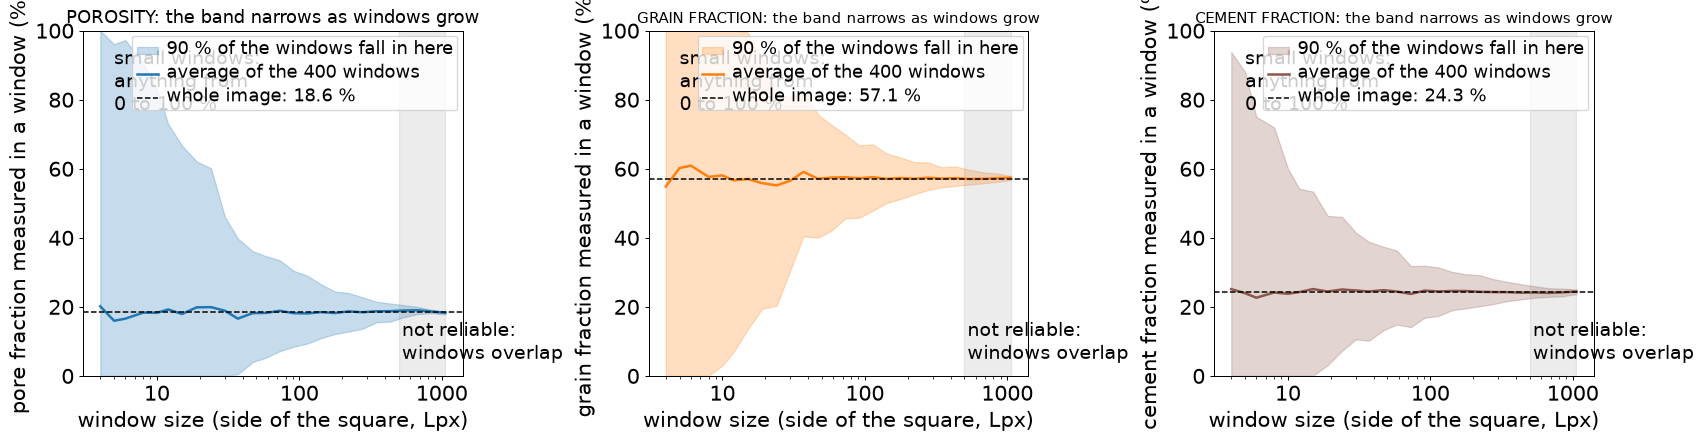

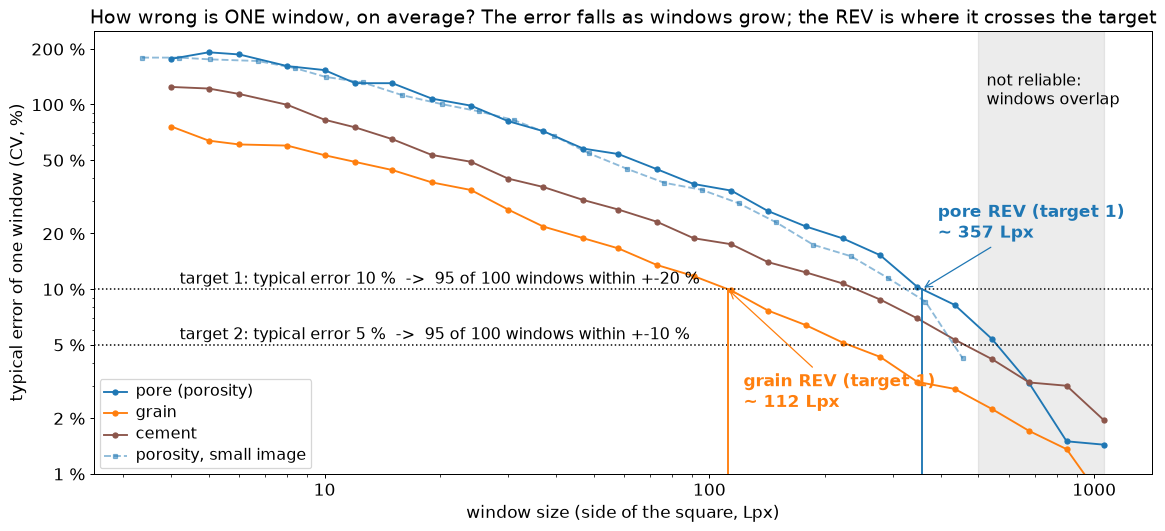

log-log slope of CV(L) for porosity, L = 30-300 Lpx: -0.75


,REV (CV=5%) Lpx,REV (CV=10%) Lpx
grain,229.0,112.0
pore,NaN,357.0
cement,NaN,240.0
pore (small image),431.0,323.0


In [2]:
sizes = np.unique(np.round(np.logspace(np.log10(4), np.log10(min(H, W) - 1), 26)).astype(int))
rev = {n: rev_random_windows(m, sizes, n=400, seed=1) for n, m in masks.items()}
# small image: its own pixels converted to Lpx
rev_small = rev_random_windows(ph_small == PORE, sizes, n=400, seed=1); rev_small['L'] = rev_small['L'] * SCALE

def rev_size(df, target=0.05):
    d = df[df['L'] <= 500]
    ok = d[d.cv <= target]
    if ok.empty: return np.nan
    i = d.index.get_loc(ok.index[0])
    if i == 0: return d['L'].iloc[0]
    a, b = d.iloc[i - 1], d.iloc[i]   # log-log interpolation
    return float(np.exp(np.interp(np.log(target), [np.log(b.cv), np.log(a.cv)], [np.log(b['L']), np.log(a['L'])])))

from matplotlib.ticker import FuncFormatter
cols = {'grain': 'tab:orange', 'pore': 'tab:blue', 'cement': 'tab:brown'}
ref = rev['pore'].query('L >= 30 and L <= 300')
BAD = 500                                        # windows larger than this overlap too much (not trusted)
px_fmt = FuncFormatter(lambda v, _: f'{v:g}')

# ---- Plot 1: one panel per phase - what each window measures
fig, ax = plt.subplots(1, 3, figsize=(19, 5), sharey=False)
for a_, n in zip(ax, ['pore', 'grain', 'cement']):
    d = rev[n]; whole = 100 * masks[n].mean()
    a_.fill_between(d['L'], 100 * d.p5, 100 * d.p95, color=cols[n], alpha=0.25, label='90 % of the windows fall in here')
    a_.plot(d['L'], 100 * d['mean'], color=cols[n], lw=2, label='average of the 400 windows')
    a_.axhline(whole, color='k', ls='--', lw=1.2, label=f'whole image: {whole:.1f} %')
    a_.axvspan(BAD, d['L'].max(), color='gray', alpha=0.15)
    a_.text(BAD * 1.05, 3, 'not reliable:\nwindows overlap', fontsize=9, va='bottom')
    a_.text(5, 95, 'small windows:\nanything from\n0 to 100 %', fontsize=9, va='top')
    a_.set_xscale('log'); a_.xaxis.set_major_formatter(px_fmt)
    a_.set_ylim(0, 100)
    a_.set_xlabel('window size (side of the square, Lpx)')
    a_.set_ylabel(f'{n} fraction measured in a window (%)')
    a_.set_title(f'{"POROSITY" if n == "pore" else n.upper() + " FRACTION"}: the band narrows as windows grow', fontsize=11)
    a_.legend(loc='upper right', fontsize=8.5)
plt.tight_layout(); plt.show()

# ---- Plot 2: typical error of one window, and where each REV is reached
fig, a_ = plt.subplots(figsize=(13, 6))
for n in ['pore', 'grain', 'cement']:
    d = rev[n]
    a_.plot(d['L'], 100 * d.cv, 'o-', ms=4, color=cols[n], label=n if n != 'pore' else 'pore (porosity)')
a_.plot(rev_small['L'], 100 * rev_small.cv, 's--', ms=3, color='tab:blue', alpha=0.5, label='porosity, small image')
for lvl, txt in [(10, 'target 1: typical error 10 %  ->  95 of 100 windows within +-20 %'),
                 (5, 'target 2: typical error 5 %  ->  95 of 100 windows within +-10 %')]:
    a_.axhline(lvl, color='k', ls=':', lw=1.2)
    a_.text(4.2, lvl * 1.07, txt, fontsize=9.5)
for n, yoff in [('pore', 1.9), ('grain', 0.23)]:
    L10 = rev_size(rev[n], 0.10)
    a_.plot([L10, L10], [1, 10], color=cols[n], lw=1.5)
    a_.annotate(f'{n} REV (target 1)\n~ {L10:.0f} Lpx', xy=(L10, 10), xytext=(L10 * 1.1, 10 * yoff), color=cols[n],
                fontsize=10, fontweight='bold', arrowprops=dict(arrowstyle='->', color=cols[n]))
a_.axvspan(BAD, rev['pore']['L'].max(), color='gray', alpha=0.15)
a_.text(BAD * 1.05, 150, 'not reliable:\nwindows overlap', fontsize=9, va='top')
a_.set_xscale('log'); a_.set_yscale('log')
a_.xaxis.set_major_formatter(px_fmt)
a_.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g} %'))
a_.set_yticks([1, 2, 5, 10, 20, 50, 100, 200])
a_.set_ylim(1, 250)
a_.set_xlabel('window size (side of the square, Lpx)')
a_.set_ylabel('typical error of one window (CV, %)')
a_.set_title('How wrong is ONE window, on average? The error falls as windows grow; '
             'the REV is where it crosses the target', fontsize=11)
a_.legend(loc='lower left', fontsize=9)
plt.tight_layout(); plt.show()

rev_tab = pd.DataFrame({n: {'REV (CV=5%) Lpx': rev_size(d), 'REV (CV=10%) Lpx': rev_size(d, 0.10)} for n, d in rev.items()}).T
rev_tab.loc['pore (small image)'] = [rev_size(rev_small), rev_size(rev_small, 0.10)]
slope = np.polyfit(np.log(ref['L']), np.log(ref.cv), 1)[0]
print(f'log-log slope of CV(L) for porosity, L = 30-300 Lpx: {slope:.2f}')
rev_tab.round(0)

**Reading plot 1 (one panel per phase).** **x axis:** window size in pixels (log scale: 10, 100, 1000). **y axis:**
the fraction measured inside one window, in %. The **line** is the average of the 400 windows; the **shaded band** is
where 90 % of the windows fall; the **dashed line** is the value of the whole image; the **grey zone** (> 500 Lpx) is not
reliable because the windows overlap. Read it from left to right: small windows give anything from 0 to 100 % (wide
band); as windows grow, the band **narrows** around the whole-image value. The narrower the band, the more one window
can be trusted. The porosity band stays wide longest: porosity is the hardest property to represent.

**Reading plot 2.** **y axis:** the typical error of ONE window (the CV), in %. 100 % = one window is typically wrong
by as much as the value itself; 10 % = wrong by one tenth. It falls as windows grow. The two dotted lines are the
precision targets: **target 1** (typical error 10 % -> 95 of 100 windows within +-20 %) and **target 2** (5 % -> within
+-10 %). The **REV is where a curve crosses a target**: porosity crosses target 1 at **~ 360 Lpx**, grain fraction at
~ 110 Lpx. Porosity does not reach target 2 before the grey zone. The dashed blue curve (small image) follows the large
image: same rock, same behavior.

**Reading the table.** The same crossing points as numbers, in Lpx:
- **REV (CV=10%)** = target 1 (+-20 %): porosity **~ 360**, grain ~ 110, cement ~ 240.
- **REV (CV=5%)** = target 2 (+-10 %): grain ~ 230. For porosity and cement **NaN** (no value): the target is not reached
  up to 500 Lpx, the largest size that can be tested. For porosity it is predicted in section 3 (~ 800 Lpx).
- **pore (small image)**: similar porosity REV (~ 320 at target 1).

The printed slope (-0.75) describes how fast the error shrinks with window size; it is used in section 3.

## 2. Two-point correlation and indicator variogram

**The question.** *"I stand on a pore pixel. If I walk a few pixels away, what is the chance that I am still in a
pore?"*
- Walk **0 pixels**: same spot, certainly pore: **100 %**.
- Walk **1 pixel**: very likely still inside the same pore.
- Walk **very far**: the pore where I started no longer matters; the chance is just the normal share of pore in the
  rock, the porosity: **18.6 %**.

**Why it matters.** This section measures **how big the "pieces" of
pore (and grain, and cement) are, and whether they are the same in every direction**. How fast the chance drops from
100 % to 18.6 % gives that size. It is useful because:

1. **It answers Challenge 1 (heterogeneity).** "Heterogeneous" means the rock is not the same everywhere. To
   describe that, we need the **scale** at which it changes: from one grain to the next, or in large porous and
   tight zones? This section gives the small-scale answer.
2. **It explains the REV and lets us predict it (sections 1 and 3).** A window gives a reliable porosity only if it
   contains many independent pieces of pore and grain. The bigger the pieces, the bigger the window must be.
   Section 3 uses this curve to calculate the REV from theory and compares it with the REV measured in section 1.
3. **It checks for layers.** Sedimentary rocks often have layers (bedding), which would make the rock different
   along the layers than across them: the horizontal and vertical curves would differ, and the 2D map would be
   stretched instead of round.
4. **It is the standard tool of reservoir geostatistics.** The variogram (center plot) is what geologists use to
   fill a 3D reservoir model with porosity values ("how far apart must two points be before they are unrelated?").
   Here it is measured at the pore scale.

**Real numbers from the large image** (start on a pore pixel, walk right or down):

| Distance walked | Chance still in a pore (walking right) | (walking down) |
|---|---|---|
| 0 Lpx | 100 % | 100 % |
| 1 Lpx | 91 % | 90 % |
| 3 Lpx | 73 % | 72 % |
| 6 Lpx | 53 % | 50 % |
| 10 Lpx | 37 % | 33 % |
| 20 Lpx | 24 % | 23 % |
| 50 Lpx | 19 % | 21 % |
| 200 Lpx | 18 % | 18 % |

Within a few pixels you are usually still in the same pore; after ~ 20 pixels the chance is back to ~ 18.6 %, so
where you started no longer matters. Right and down give almost the same numbers: no preferred direction.

**What the code does.** It computes this chance for every distance and every direction (for pore, grain and cement)
and shows it in four ways:
1. **Correlation curve C(r)** (left plot): the same chance, rescaled so that **1 = certainly the same as the
   starting point** and **0 = no connection** (just the normal share). r = the distance walked.
2. **Variogram** (center plot): the same information turned upside down, the form used in geostatistics. It starts
   at 0 and levels off where points stop being related.
3. **Horizontal vs vertical** (right plot): the curve walking only sideways or only up and down. Layers would make
   them differ.
4. **2D map**: all directions at once. A round spot = the same in every direction; layers would stretch it.

The table after the plots gives the **correlation length**: the distance where C(r) has dropped to about one third
(1/e = 0.37). It is a single number for "how far a pore reaches".

S2(r) is the probability that two points separated by r both fall in pore space. Normalized:
**C(r) = (S2 - phi^2) / (phi - phi^2)**, which is 1 at r = 0 and 0 when pores at distance r are independent.
The indicator semivariogram is gamma(r) = phi - S2(r); its **sill** is phi(1-phi).
Computed exactly for all lags with FFT (zero-padded, normalized by the number of pixel pairs).

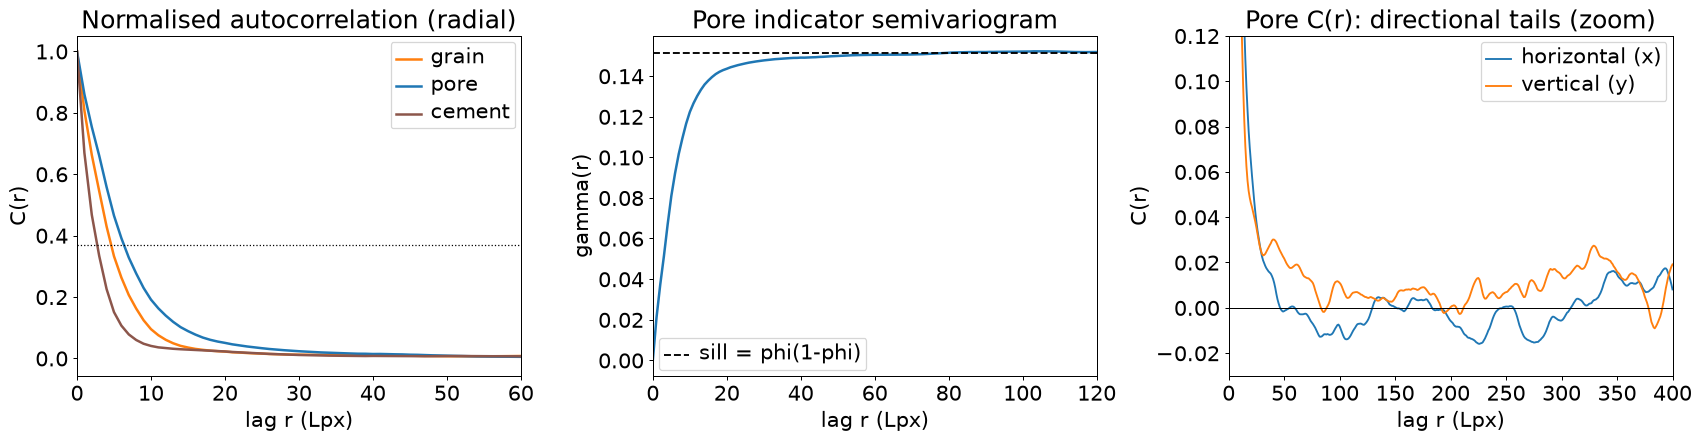

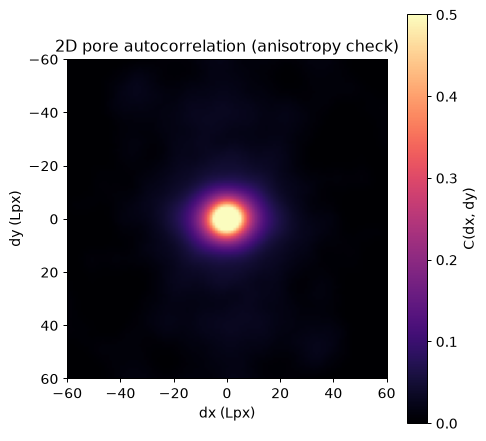

,corr. length 1/e (radial),corr. length 1/e (x),corr. length 1/e (y)
grain,4.64,4.72,4.75
pore,6.37,6.82,6.18
cement,2.75,2.83,2.78


In [3]:
cf = {}
for n, m in masks.items():
    cf[n], _ = correlation_functions(m, rmax=400)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for n, d in cf.items():
    ax[0].plot(d.r, d.C_radial, color=cols[n], lw=2, label=n)
ax[0].axhline(np.exp(-1), color='k', ls=':', lw=1); ax[0].set_xlim(0, 60)
ax[0].set_xlabel('lag r (Lpx)'); ax[0].set_ylabel('C(r)'); ax[0].set_title('Normalised autocorrelation (radial)'); ax[0].legend()

d = cf['pore']; phi = masks['pore'].mean()
ax[1].plot(d.r, d.gamma_radial, lw=2); ax[1].axhline(phi * (1 - phi), color='k', ls='--', label='sill = phi(1-phi)')
ax[1].set_xlabel('lag r (Lpx)'); ax[1].set_ylabel('gamma(r)'); ax[1].set_title('Pore indicator semivariogram'); ax[1].legend(); ax[1].set_xlim(0, 120)

ax[2].plot(d.r, d.C_x, label='horizontal (x)'); ax[2].plot(d.r, d.C_y, label='vertical (y)')
ax[2].axhline(0, color='k', lw=0.8); ax[2].set_xlim(0, 400); ax[2].set_ylim(-0.03, 0.12)
ax[2].set_xlabel('lag r (Lpx)'); ax[2].set_ylabel('C(r)'); ax[2].set_title('Pore C(r): directional tails (zoom)'); ax[2].legend()
plt.tight_layout(); plt.show()

s2, phi = two_point_map(masks['pore']); cy, cx = np.array(s2.shape) // 2; R = 60
Cmap = (s2[cy - R:cy + R + 1, cx - R:cx + R + 1] - phi ** 2) / (phi - phi ** 2)
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(Cmap, extent=[-R, R, R, -R], cmap='magma', vmin=0, vmax=0.5); plt.colorbar(im, label='C(dx, dy)')
ax.set_xlabel('dx (Lpx)'); ax.set_ylabel('dy (Lpx)'); ax.set_title('2D pore autocorrelation (anisotropy check)')
plt.tight_layout(); plt.show()

corr_tab = pd.DataFrame({n: {f'corr. length 1/e ({k})': correlation_length(d.r.values, d[c].values)
                             for k, c in [('radial', 'C_radial'), ('x', 'C_x'), ('y', 'C_y')]} for n, d in cf.items()}).T
corr_tab.round(2)

**Reading the plots.**
- **Left, x axis:** distance r between two points (Lpx). **y axis:** correlation C(r), 1 = both points always in the
  same phase, 0 = unrelated. It falls to 1/e (dotted line) within **~ 6 Lpx for pores**, 4.6 for grains and 2.8 for
  cement: about half a grain diameter. Beyond ~ 20 Lpx, a point says almost nothing about another.
- **Center:** the same information as a variogram (the geostatistics form): gamma(r) rises from 0 and levels off at the
  sill phi(1-phi) (dashed) after ~ 20-30 Lpx.
- **Right:** correlation along x (horizontal) and y (vertical), zoomed on the tail. The vertical tail stays slightly
  positive (~ 0.01-0.02) up to ~ 400 Lpx, a weak hint of horizontal structure.
- **2D map:** correlation for every direction around the center (dx, dy). The bright spot is **round**: no preferred
  direction at pore scale.
- **Table:** correlation lengths (distance where C = 1/e) in all directions and along x and y. x and y differ by less
  than 10 %: the pore structure is isotropic.

## 3. Integral range: predicting the REV from the correlation function

**The question.** Section 1 measured the REV directly; statistical theory can also predict it from the correlation. If theory and measurement agree, the heterogeneity is well understood and 'stationary' (the same everywhere, only randomly patchy). If they disagree, there is extra large-scale structure.

**Why it matters.** This section **checks the REV with theory and
predicts it beyond what the image can measure**. It is useful because:

1. **It confirms that we understand the REV.** If the REV predicted from the correlation (section 2) matches the
   REV measured with windows (section 1), the heterogeneity is explained by the size of the pore pieces alone.
2. **It gives the REV where the image is too small to measure it.** The strict porosity REV (~ 800 Lpx) cannot be
   measured directly (windows that large overlap), but it can be predicted.
3. **It detects large-scale structure.** If measurement and theory disagreed, there would be extra structure
   (zones, layers) that the small-scale correlation does not explain. The integral range also shows the size of the
   largest porous zones (where its curve levels off).
4. **It is the basis of upscaling.** The integral range says how many independent "pieces" a sample contains, which
   is how properties measured on small samples are transferred to larger volumes.

**What.** The integral range A3: the effective area of one 'independent unit' of the rock. It is estimated from the window scatter of section 1, and used to predict the CV and the REV.

**What is an independent unit? (the idea behind A3, in plain words)**

- Inside a small area, pixels are **linked**: if one pixel is pore, its neighbors are probably pore too (it is the
  same pore). Two areas far enough apart are **unrelated**: knowing one tells nothing about the other (section 2).
- An **independent unit** is the smallest area whose content is unrelated to the next one. It is **not a visible
  object** but a statistical idea: imagine a grid of such squares laid over the image; each square counts as one
  independent sample of the rock.
- **A3 is the area of one independent unit.** For pores, A3 ~ 362 Lpx^2, i.e. about **19 x 19 Lpx**: roughly one grain
  with its surrounding pore space.

**Why it predicts the REV.** A window's porosity is an average over the independent units it contains, and an
average of many independent things is more precise than an average of a few, like judging a coin from 400 tosses
instead of 4:
- a 360 x 360 Lpx window contains about 129,600 / 362 ~ **358 units**;
- the typical error of a window shrinks like 1 / sqrt(number of units). With 358 units this predicts a typical
  error of ~ 11 %; section 1 measured **10.6 %**. The prediction works.
- Reversing it (how many units are needed for a typical error of 10 % or 5 %?) gives the window size, i.e. the REV:
  ~ 400 Lpx and **~ 800 Lpx**. The second cannot be measured in this image (windows would overlap), but it can be
  predicted.

**How A3 is found.** Section 1 measured the typical error for each window size; knowing the error and the window
size, one can calculate how large the units must be to produce that error (formula below). This gives A3 for each
window size: it grows while the windows are too small to contain whole porous zones, then levels off (a plateau).
The plateau value is A3, and the window size where it levels off (~ 250 Lpx for pores) is the size of the largest
porous zones.

**How.**

For a stationary random medium, the variance of the phase fraction in a window of area A >> correlation area is
(Lantuejoul, 1991; Kanit et al., 2003):

**Var(phi_A) ~ phi(1-phi) A3 / A**, with integral range **A3 = integral of C(r) 2 pi r dr**.

So CV(L) = sqrt((1-phi)/phi x A3) / L, a slope of -1 in log-log. Integrating C(r) directly is unstable, because a
weak positive tail of C(r) (~ 0.01 out to hundreds of Lpx) dominates the integral. We therefore follow Kanit et
al. (2003) and estimate A3 from the **window variance itself**, as the **apparent integral range**

**A3(L) = CV(L)^2 x L^2 x phi / (1-phi)**

- A3(L) grows with L while the window is still smaller than the heterogeneity it samples.
- A3(L) reaches a **plateau** once the window exceeds the largest correlated structure. The plateau is the
  integral range, and the L where it is reached is the **largest scale of heterogeneity**.
- A3(L) growing without limit would mean heterogeneity at all scales (no REV inside the thin section).

As a check, A3 from integrating C(r) up to r = 60 Lpx (before the noisy tail) is also reported.

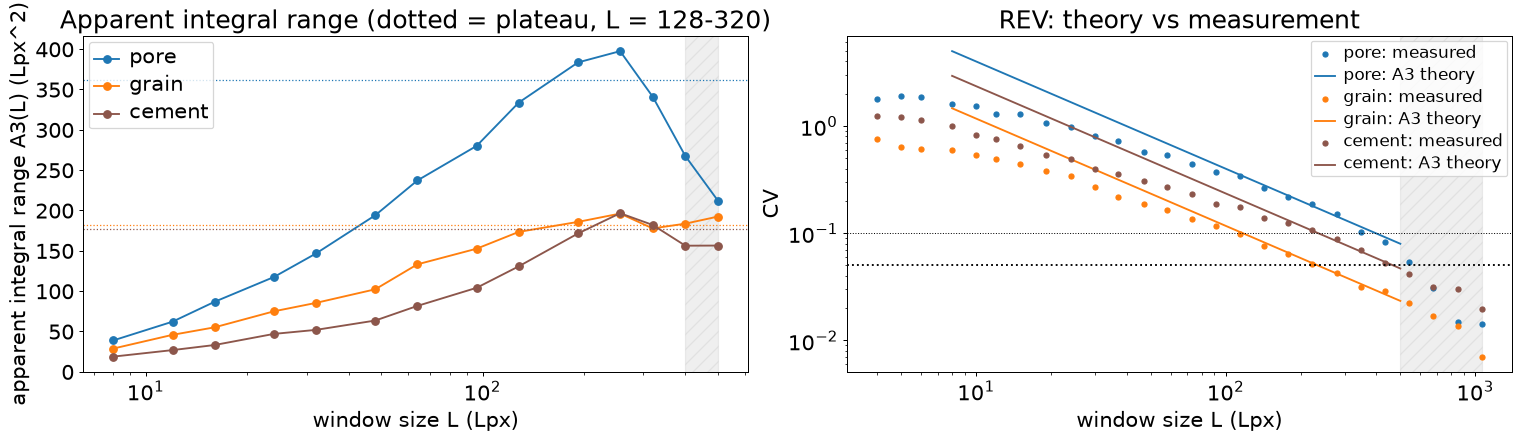

,fraction,A3 plateau (Lpx^2),"A3 from C(r), r<=60",sqrt(A3) (Lpx),REV theory CV=10% (Lpx),REV theory CV=5% (Lpx),REV measured CV=10% (Lpx)
phase,,,,,,,
pore,0.2,362.2,349.0,19.0,398.5,797.1,356.6
grain,0.6,181.8,216.4,13.5,116.9,233.8,111.5
cement,0.2,176.7,155.8,13.3,234.4,468.8,240.1


In [4]:
Lg = np.array([8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, 320, 400, 500])
rows, app = [], {}
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for n in ['pore', 'grain', 'cement']:
    m = masks[n]; p = m.mean()
    d = rev_random_windows(m, Lg, n=1500, seed=4)
    d['A3_apparent'] = d.cv ** 2 * d['L'] ** 2 * p / (1 - p)
    app[n] = d
    A3 = d.query('L >= 128 and L <= 320').A3_apparent.median()       # plateau
    c = cf[n]; A3_c = np.trapezoid(c.C_radial[:61] * 2 * np.pi * c.r[:61], c.r[:61])
    ax[0].semilogx(d['L'], d.A3_apparent, 'o-', color=cols[n], label=n)
    ax[0].axhline(A3, color=cols[n], ls=':', lw=1)
    ax[1].loglog(rev[n]['L'], rev[n].cv, 'o', ms=4, color=cols[n], label=f'{n}: measured')
    ax[1].loglog(Lg, np.sqrt((1 - p) / p * A3) / Lg, '-', color=cols[n], label=f'{n}: A3 theory')
    rows.append({'phase': n, 'fraction': p, 'A3 plateau (Lpx^2)': A3, 'A3 from C(r), r<=60': A3_c,
                 'sqrt(A3) (Lpx)': np.sqrt(A3),
                 'REV theory CV=10% (Lpx)': np.sqrt((1 - p) / p * A3) / 0.10,
                 'REV theory CV=5% (Lpx)': np.sqrt((1 - p) / p * A3) / 0.05,
                 'REV measured CV=10% (Lpx)': rev_size(rev[n], 0.10)})
ax[0].axvspan(400, 500, color='gray', alpha=0.12, hatch='//')
ax[0].set_xlabel('window size L (Lpx)'); ax[0].set_ylabel('apparent integral range A3(L) (Lpx^2)')
ax[0].set_title('Apparent integral range (dotted = plateau, L = 128-320)'); ax[0].legend()
ax[1].axhline(0.05, color='k', ls=':'); ax[1].axhline(0.10, color='k', ls=':', lw=0.8)
ax[1].axvspan(500, rev['pore']['L'].max(), color='gray', alpha=0.12, hatch='//')
ax[1].set_xlabel('window size L (Lpx)'); ax[1].set_ylabel('CV'); ax[1].legend(fontsize=8); ax[1].set_title('REV: theory vs measurement')
plt.tight_layout(); plt.show()
ir_tab = pd.DataFrame(rows).set_index('phase'); ir_tab.round(1)

**Reading the plots.**
- **Left, x axis:** window size L (Lpx). **y axis:** apparent integral range A3(L) (Lpx^2). It grows while windows are
  smaller than the porous zones, then levels off (plateau, dotted line) once windows are larger than the biggest porous zones.
  For pores it grows up to **L ~ 250 Lpx**: the porous zones are about that size.
- **Right:** measured CV (dots) and CV predicted from A3 (lines) against window size. They agree well for L > ~ 100 Lpx.
- **Table:** A3 and sqrt(A3) (the side of one independent unit) per phase, and the predicted vs measured REV. For
  porosity the prediction is 399 Lpx vs 357 Lpx measured: **theory and measurement agree within ~ 10 %**.

## 4. Lacunarity

**The question.** Correlation says how far a pore 'reaches'. It does not say whether pores gather into clusters separated by tight zones. Lacunarity measures that 'gappiness' at every scale.

**Why it matters.** This section tests **whether the pores are
patchy**: gathered in porous zones separated by tight zones. It is useful because:

1. **It answers Challenge 1 at the large scale.** Section 2 described the small scale (single pores); lacunarity
   looks at all scales, including groups of many pores.
2. **It separates arrangement from shape.** Comparing the real image with the same pore bodies moved to random
   places shows whether the pores are *arranged* in clusters, not just shaped irregularly.
3. **It gives the size of the porous zones.** The scale where the real pores are most clustered compared with random is
   the typical size of the porous zones.
4. **It matters for flow.** Porous zones can form preferred flow paths, and tight zones can act as barriers; a
   patchy rock behaves differently from an evenly porous one with the same porosity.

**What.** The lacunarity curve of the real pores, compared with two artificial versions of the same image: random pixels (no structure) and randomly moved pore bodies (real pore shapes, but no clustering).

**How.**

Gliding-box lacunarity Lambda(r) = E[M^2]/E[M]^2, where M is the pore "mass" in an r x r box.
Lambda -> 1 means the phase looks homogeneous at that box size, and large Lambda means gaps/clusters.
Two reference patterns bracket the real one:
- **random pixels** with the same porosity (no spatial structure),
- **randomly relocated pore bodies**: each pore body keeps its shape and size but is moved to a random position.
  This removes any clustering of pores *between* bodies but keeps the pore-scale texture.

If the real curve lies above the relocated-body curve at large r, pores are clustered at scales larger than a pore.

### Lacunarity in one picture

![Lacunarity explained](../outputs/figures/lacunarity_simple.png)

*Figure generated by `scripts/lacunarity_diagram.py` (rows 1-2: made-up images; row 3: the real large image).*

**The idea, step by step.**
1. **(a), (b): two made-up images with the same porosity (19 %).** In (a) the pores are spread evenly; in (b) they
   are gathered in four zones. Porosity alone cannot tell them apart.
2. **Cut each image into boxes** (red grid) and measure the porosity inside each box (the numbers).
3. **(c), (d): compare the boxes.** Evenly spread pores give boxes that are all similar (~ 10-30 %). Pores gathered in
   zones give many almost empty boxes and a few very full ones.
4. **Lacunarity is one number for how uneven the boxes are**: close to **1** = all boxes similar (even); larger =
   uneven, with gaps and clusters (here 1.14 vs 1.88). Formally: average of (box porosity)^2 / (average box porosity)^2.
5. **Repeat for every box size.** Tiny boxes are always uneven (a box of 1 pixel is either pore or not); very large
   boxes are always similar (each contains a bit of everything). What matters is what happens in between.

**The real rock (row 3).**
- **(e)** the real pores; **(f)** exactly the same pores, each moved to a random place (same shapes and sizes, same
  porosity, but no zones).
- **(g)** unevenness (lacunarity - 1) for every box size. For small boxes the two curves are the same: the pores have
  the same shapes. For **large boxes (~ 20-500 Lpx) the real pores stay more uneven** than the moved ones (about 2x at
  170 Lpx): the real pores are **gathered in porous zones**, and this comes from **where** they are, not from their
  shapes.

The code below computes the same curves (plus random pixels and grains as references), averaged over 10 random
relocations.

### What each curve is (plots below)

Each curve is the lacunarity (Lambda, "how uneven the boxes are": 1 = all boxes alike, higher = gaps and clusters)
of **one image**, for every box size. Four images are compared, all with the same amount of pore (18.6 %) except
the grains:

| Curve (left plot) | The image it comes from | How that image is made | Why it is there |
|---|---|---|---|
| **blue line, circles** - "pore (real)" | the **real pores** of the large image | the pore map of notebook 01 | what we want to understand |
| **orange dashed line, squares** - "pore bodies randomly relocated" | the **same pores, moved to random places** | every pore body is kept with its exact shape and size, and placed at a random position without overlapping (10 random versions, averaged) | reference **"real pore shapes, but no zones"** |
| **green dotted line, triangles** - "random pixels" | **salt-and-pepper noise** | every pixel is made pore with an 18.6 % chance, independently of its neighbors: no pore shapes at all | reference **"no structure at all"**: the most even arrangement possible |
| **orange solid line, diamonds** - "grain (real)" | the **real grains** | the grain map of notebook 01 (57 % of the image) | comparison with the other phase |

**How to compare them**
- **green vs orange dashed:** the difference is caused by the **size and shape of the pores** (real pores are blobs
  ~ 10 Lpx across; random pixels are single dots).
- **orange dashed vs blue:** the difference is caused by **where the pores are**. If blue stays above orange dashed,
  the real pores are gathered in porous zones.
- **grain (orange solid)** is much lower than the pore curves: grains fill most of the image, so boxes are always
  fairly similar.

**Right plot ("excess lacunarity").** It zooms in on the gap between **blue and orange dashed**:
(real - 1) / (relocated - 1) = how many times more uneven the real pores are than the same pores placed at random.
**1 (dotted line) = no difference** (no zones); **above 1 = the real pores are gathered in zones**.

porosity real 0.1857, relocated (mean of 10) 0.1857


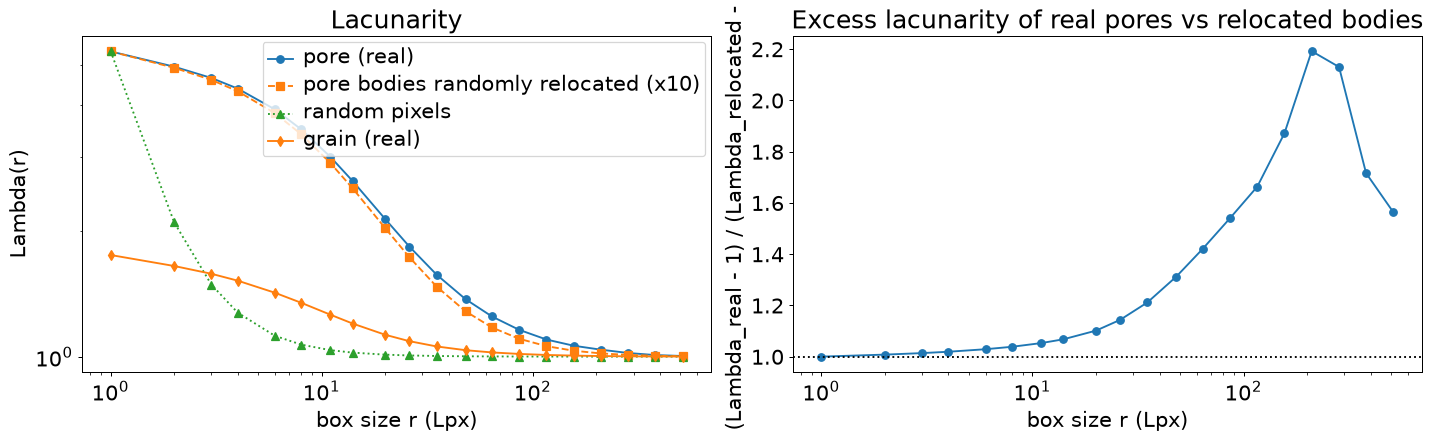

r,1,4,11,26,64,156,380
real,5.385,4.386,3.008,1.835,1.248,1.062,1.009
relocated,5.385,4.323,2.907,1.730,1.174,1.033,1.005
random px,5.393,1.274,1.036,1.006,1.001,1.000,1.000


In [5]:
rng = np.random.default_rng(0)
Lp = np.load('../outputs/labels_pore_large.npy')
rand_px = rng.random(ph.shape) < masks['pore'].mean()

def relocate_bodies(L, rng, tries=200):
    """Move every pore body to a random position without overlap (largest first), preserving porosity."""
    from scipy import ndimage as ndi
    out = np.zeros(L.shape, bool)
    objs_ = [(L[sl] == lab) for sl, lab in zip(ndi.find_objects(L), range(1, L.max() + 1)) if sl is not None]
    for patch in sorted(objs_, key=lambda p: -p.sum()):
        h, w = patch.shape
        for _ in range(tries):
            y, x = rng.integers(0, L.shape[0] - h + 1), rng.integers(0, L.shape[1] - w + 1)
            if not (out[y:y + h, x:x + w] & patch).any():
                out[y:y + h, x:x + w] |= patch
                break
    return out

box = np.unique(np.round(np.logspace(0, np.log10(512), 22)).astype(int))
lac_real = lacunarity(masks['pore'], box)
lac_rand = lacunarity(rand_px, box)
relocs = [relocate_bodies(Lp, rng) for _ in range(10)]
print(f'porosity real {masks["pore"].mean():.4f}, relocated (mean of 10) {np.mean([r.mean() for r in relocs]):.4f}')
lac_reloc = np.mean([lacunarity(r, box) for r in relocs], axis=0)
lac_grain = lacunarity(masks['grain'], box)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].loglog(box, lac_real, 'o-', label='pore (real)'); ax[0].loglog(box, lac_reloc, 's--', label='pore bodies randomly relocated (x10)')
ax[0].loglog(box, lac_rand, '^:', label='random pixels'); ax[0].loglog(box, lac_grain, 'd-', color='tab:orange', label='grain (real)')
ax[0].set_xlabel('box size r (Lpx)'); ax[0].set_ylabel('Lambda(r)'); ax[0].legend(); ax[0].set_title('Lacunarity')
ax[1].semilogx(box, (lac_real - 1) / (lac_reloc - 1), 'o-')
ax[1].axhline(1, color='k', ls=':'); ax[1].set_xlabel('box size r (Lpx)')
ax[1].set_ylabel('(Lambda_real - 1) / (Lambda_relocated - 1)'); ax[1].set_title('Excess lacunarity of real pores vs relocated bodies')
plt.tight_layout(); plt.show()
pd.DataFrame({'r': box, 'real': lac_real, 'relocated': lac_reloc, 'random px': lac_rand}).iloc[::3].round(3).set_index('r').T

**Reading the plots.**
- **Left, x axis:** box size r (Lpx, log). **y axis:** lacunarity Lambda (log): 1 = the pores look evenly spread at
  that box size; higher = gaps and clusters. All curves fall towards 1 as the box grows.
- The real pore curve (blue) lies **above** the moved-bodies curve (orange dashed) for boxes larger than ~ 10 Lpx:
  the real pores are more clustered than their shapes alone explain. The random-pixel curve drops fastest (no
  structure). Grains (orange solid) are much less gappy than pores.
- **Right:** the excess of real over moved lacunarity. It peaks at ~ **2.2x around 200 Lpx**: pores gather into
  porous zones of about that size.
- **Table:** the values behind the left plot, for a few box sizes.

## 5. Point-pattern statistics of grain and pore centroids

**The question.** Treating each grain or pore as a point (its center) gives a second, independent test of clustering, and tells whether the large pores in particular gather together.

**Why it matters.** This section checks **whether grains, pores
and especially the large pores are grouped, spread at random, or evenly spaced**, treating each object as a point. It is useful because:

1. **It is an independent check of section 4.** Lacunarity works with pixels; this works with objects (their
   centers). If both find clustering at the same scale, the result is robust.
2. **It focuses on the large pores.** The largest pores hold most of the pore space (notebook 03). Whether they
   gather together matters most for fluid storage and flow.
3. **It separates geology from geometry.** Objects cannot overlap, so their centers are always somewhat evenly
   spaced at short distances. The tests are designed so that this trivial effect is not mistaken for a geological
   signal.
4. **It uses standard, well-known methods** (Clark-Evans, Ripley's K), widely used in ecology and geology, so the
   results can be compared with other studies.

**What.** Two classic point-pattern tests on the object centers: the Clark-Evans nearest-neighbor index and Ripley's K (as L(r) - r), compared with random simulations (CSR = complete spatial randomness: points placed purely at random).

**How.**

- **Clark-Evans R** = mean nearest-neighbor distance / expected under complete spatial randomness (CSR), with
  the Donnelly edge correction. R < 1 clustered, R ~ 1 random, R > 1 regular (inhibited).
- **Besag's L(r) - r** (from Ripley's K) against **99 Monte Carlo simulations**. Above the envelope = clustering at
  distance r, below = regularity.

Grains and pores are finite-size objects that cannot overlap, so they are *necessarily* regular at distances
below about one object diameter (hard-core effect). The informative test is therefore the **random labeling
test**: are the **largest 20 % of pore bodies** clustered *relative to all pore bodies*? Here the null model draws
the same number of points at random from all pore centroids, so the hard-core effect cancels out.

### Point patterns in one picture

![Point patterns explained](../outputs/figures/point_patterns_simple.png)

*Figure generated by `scripts/point_pattern_diagram.py` (row 1: made-up dots; row 2: the real large image).*

**Row 1: three kinds of dot arrangement** (made-up examples with the same number of dots).
- **(a) clustered:** dots in groups. Each dot's nearest neighbor (grey line) is very close: **R = 0.37 < 1**.
- **(b) random:** no rule. **R ~ 1**.
- **(c) regular:** dots keep their distance, like trees in an orchard. **R = 1.70 > 1**.

**Clark-Evans R** (the table below) = average distance to the nearest neighbor / the same for random dots.
The blue circle shows the idea of **Ripley's test**: count the neighbors within a distance r, for many distances.

**Row 2: the real rock as dots.**
- **(d)** each grain (yellow outline) is replaced by one dot at its center (red). The same is done for the pores.
- **(e)** all pore bodies (grey) and the **largest 20 %** (red). The key question of the right-hand plot below is
  whether the red dots are more grouped than a random choice of grey dots would be.

Ripley's curve is explained in detail after the plots below.

In [6]:
ce = []
for n in ['grain', 'pore']:
    p = big[big.phase == n][['cx', 'cy']].values
    ce.append({'pattern': f'{n} centroids', **clark_evans(p, W, H)})
pores = big[big.phase == 'pore']
large_p = pores[pores.area_u >= pores.area_u.quantile(0.8)][['cx', 'cy']].values
ce.append({'pattern': 'largest 20 % pores', **clark_evans(large_p, W, H)})
pd.DataFrame(ce).set_index('pattern').round(3)

,n,mean_nn,expected_csr,R,z,p_two_sided
pattern,,,,,,
grain centroids,3739,14.978,10.324,1.451,51.442,0.0
pore centroids,1751,19.395,15.135,1.281,21.879,0.0
largest 20 % pores,354,38.041,34.093,1.116,3.983,0.0


**Reading the table.** **R** = mean distance to the nearest neighbor / the value expected if the same number of
points were placed at random over the same area.

**How R is obtained.** For every center, the distance to its nearest neighbor is measured, and these distances are
averaged (`mean_nn`). This is divided by the mean distance expected for random points, 0.5 x sqrt(area / number of
points) with a correction for the image border (`expected_csr`):
- grains: 14.98 / 10.32 = **R = 1.45**;
- pores: 19.40 / 15.14 = **R = 1.28**;
- largest 20 % of pores: 38.04 / 34.09 = **R = 1.12**.

**R > 1** = more regularly spaced than random; **R ~ 1** = random; **R < 1** = clustered. **z** and **p** say whether R
differs from 1 by more than chance. All three are above 1, i.e. more regular than random. That is expected: objects of
finite size cannot overlap, so their centers cannot be very close (a hard-core effect, not a geological signal).
Whether the large pores are grouped at *larger* distances is tested with Ripley's curve below.

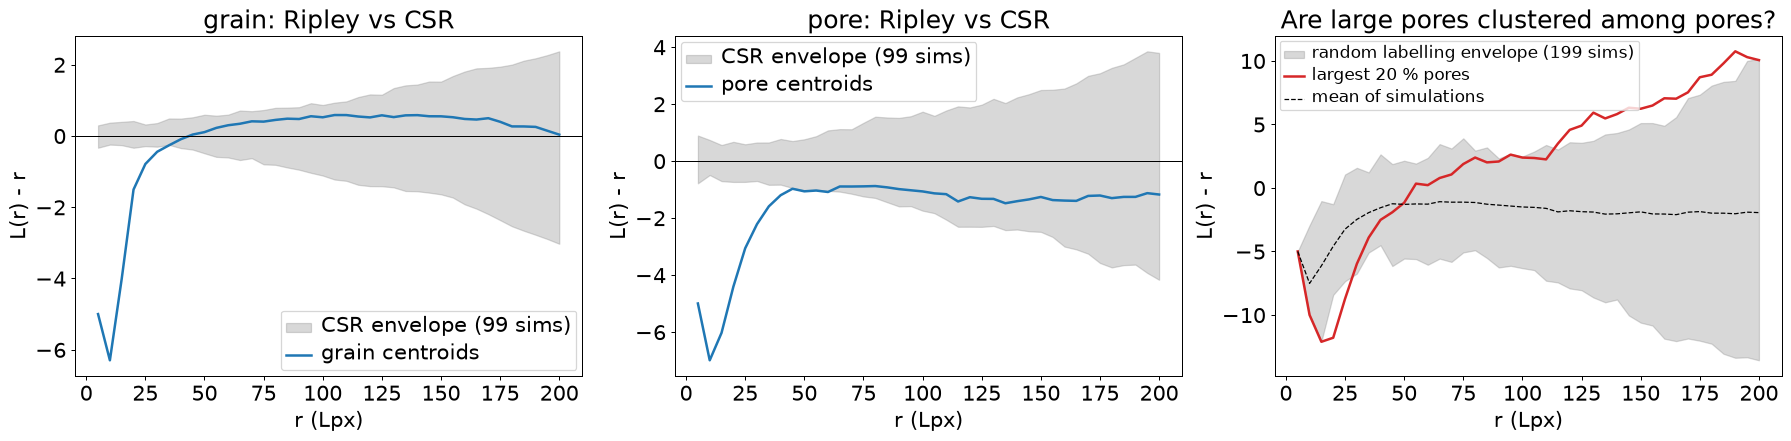

large pores above envelope (clustered) at r = [115, 120, 125, 130, 135, 140, 145, 150, 155, 160, 165, 170, 175, 180, 185, 190, 195]
large pores below envelope (regular) at r = [15, 20, 25]


In [7]:
radii = np.arange(5, 201, 5)
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, n in zip(ax[:2], ['grain', 'pore']):
    p = big[big.phase == n][['cx', 'cy']].values
    Lr = ripley_L(p, W, H, radii); lo, hi, mu = ripley_envelope(len(p), W, H, radii, nsim=99, seed=2)
    a.fill_between(radii, lo, hi, color='gray', alpha=0.3, label='CSR envelope (99 sims)')
    a.plot(radii, Lr, lw=2, label=f'{n} centroids'); a.axhline(0, color='k', lw=0.8)
    a.set_xlabel('r (Lpx)'); a.set_ylabel('L(r) - r'); a.set_title(f'{n}: Ripley vs CSR'); a.legend()

pool = pores[['cx', 'cy']].values
Lr = ripley_L(large_p, W, H, radii); lo, hi, mu = ripley_envelope(len(large_p), W, H, radii, nsim=199, seed=3, pool=pool)
ax[2].fill_between(radii, lo, hi, color='gray', alpha=0.3, label='random labelling envelope (199 sims)')
ax[2].plot(radii, Lr, lw=2, color='tab:red', label='largest 20 % pores'); ax[2].plot(radii, mu, 'k--', lw=1, label='mean of simulations')
ax[2].set_xlabel('r (Lpx)'); ax[2].set_ylabel('L(r) - r'); ax[2].set_title('Are large pores clustered among pores?'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
above = radii[Lr > hi]; below = radii[Lr < lo]
print('large pores above envelope (clustered) at r =', above.tolist())
print('large pores below envelope (regular) at r =', below.tolist())

**How to read Ripley's curve.** Ripley's test draws a circle of radius r around every center, counts the other
centers inside it, and compares the count with that of randomly placed points (CSR). This is repeated for radii from
5 to 200 Lpx.
- **x axis:** circle radius r (Lpx), the distance being tested.
- **y axis:** L(r) - r, the neighbor count rescaled so that random points give 0. **Above 0** = more neighbors than
  random (**grouped** at that distance); **below 0** = fewer neighbors (**spread out**).
- **Grey band:** what chance alone produces. The points are placed at random many times (99 for the left and center
  plots, 199 for the right plot) and the curve is calculated each time; the band spans the lowest to the highest value
  at each radius. A real curve **inside** the band shows no pattern (a random arrangement could give it); **outside**
  the band it shows a real pattern.
- **Left and center (all grains, all pores):** below the band up to ~ 40 Lpx: two objects cannot overlap, so very close
  neighbors are rarer than random (the hard-core effect seen in the table above). Beyond ~ 40 Lpx the curves are inside
  the band: randomly spread at larger distances.
- **Right (largest 20 % of pores, red):** here the band is built differently (**random labeling**). 354 pores (as many
  as the largest pores) are picked at random from all the real pores, 199 times. Every picked pore is a real pore, so
  the overlap effect is the same in the band and in the red curve and cancels out; the only question left is whether
  the *large* pores sit closer together than pores in general.
  - the **black dashed line** is the average of the 199 random choices: the value expected if pore size had nothing to
    do with position. It stays below 0 (about -2) because random pores still cannot overlap, so in this plot the red
    curve is compared with the dashed line and the band, not with 0;
  - the red curve rises above the band from **~ 115 to 195 Lpx**: large pores have more large-pore neighbors than
    chance, so they are **grouped**, at the same scale as the porous zones found with lacunarity (section 4). Two
    independent methods agree.
- The printed lines list the distances where the large-pore curve is outside the band.

## 6. Where are the porous and tight zones? Moving-window maps

**The question.** Sections 1-5 say that porous zones exist and how large they are. A map shows *where* they are, and lets us compare porosity with cement and grain size by eye.

**Why it matters.** This section **shows on a map where the
porous and tight zones are**. It is useful because:

1. **It makes the heterogeneity visible.** Sections 1-5 give numbers; the maps show the porous zones themselves.
2. **It allows a first comparison by eye.** Porosity, cement and grain size mapped side by side suggest what
   controls porosity (tested with numbers in section 7).
3. **It shows how large the local variation is.** The range of local porosity (from a few % to much more than
   average) says how different two small samples of the same rock can be.
4. **It is practical.** A map shows where to look or sample, and which parts of the section are representative.

**What.** Local porosity, cement fraction and median grain size, each measured in a 128 Lpx window moved over the whole large image.

**How.**

Window = 128 Lpx (about 9 median grain diameters, around the 10 % CV scale). Porosity, cement fraction and the local
median grain size (from grain centroids, same window) are mapped.

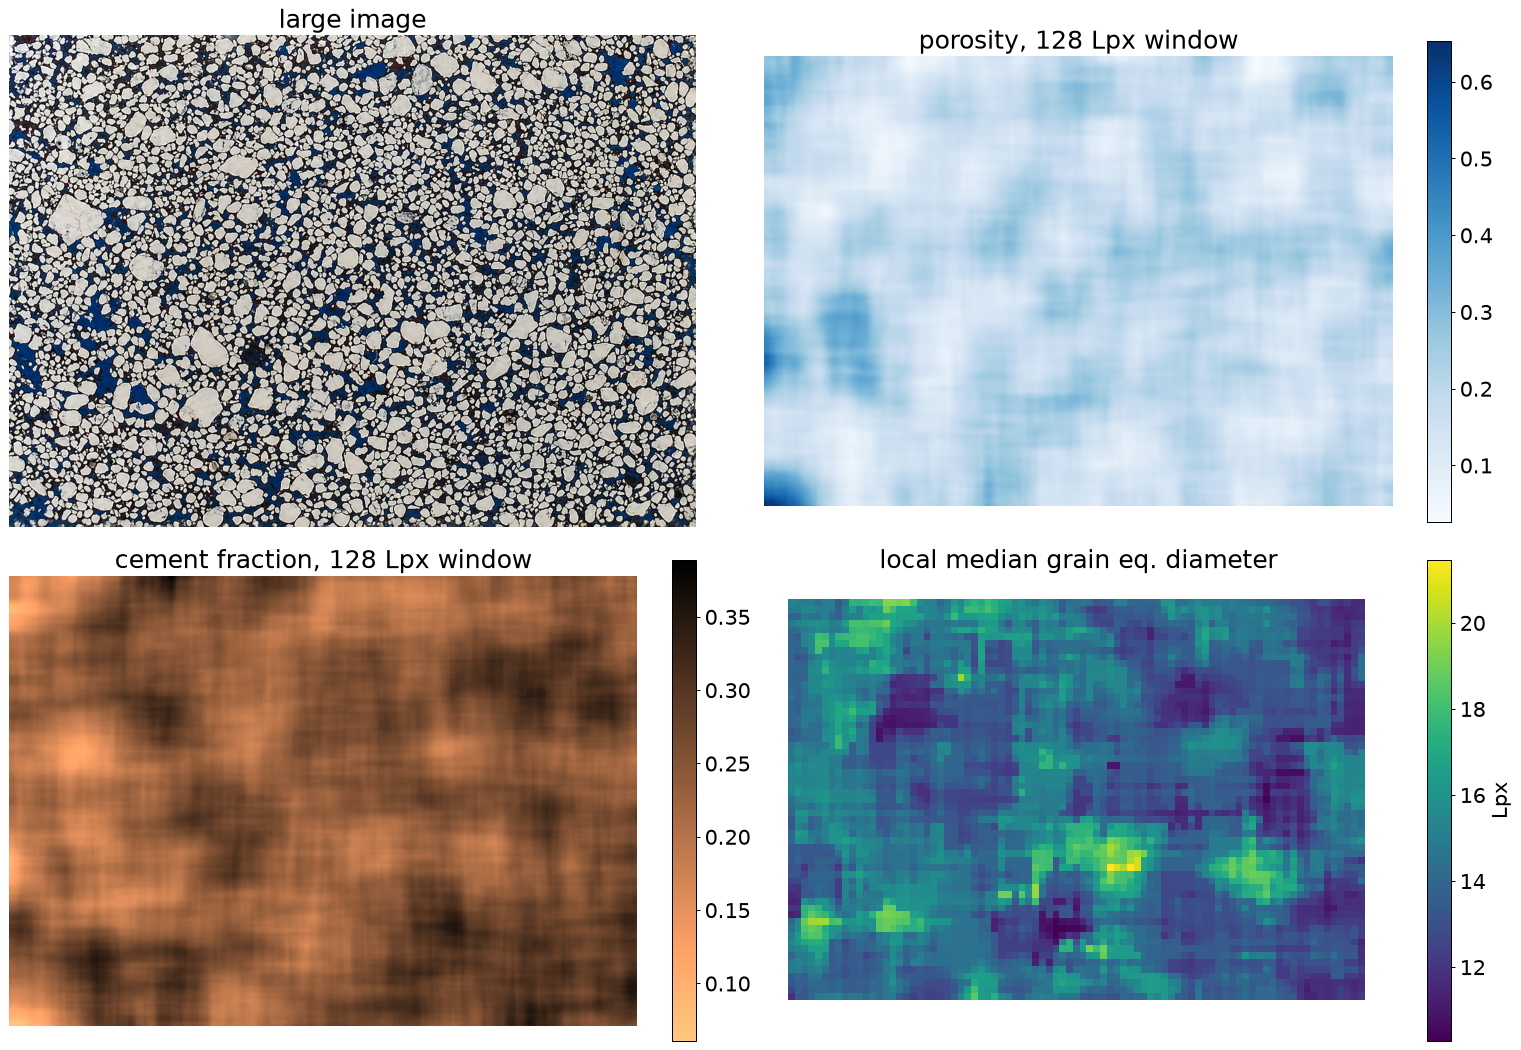

moving-window porosity: min 0.027, max 0.653, mean 0.186


In [8]:
S = 128
por_map = moving_window_fraction(masks['pore'], S)
cem_map = moving_window_fraction(masks['cement'], S)

# local median grain size on a grid (centroids within the window)
g = big[big.phase == 'grain']
gy, gx = np.mgrid[S // 2:H - S // 2 + 1:16, S // 2:W - S // 2 + 1:16]
from scipy.spatial import cKDTree
tree = cKDTree(g[['cx', 'cy']].values); D = g.eq_diameter_u.values
gs_map = np.full(gy.shape, np.nan)
for idx in np.ndindex(gy.shape):
    nb = tree.query_ball_point([gx[idx], gy[idx]], S / 2, p=np.inf)
    if len(nb) >= 10: gs_map[idx] = np.median(D[nb])

fig, ax = plt.subplots(2, 2, figsize=(17, 12))
ax[0, 0].imshow(rgb); ax[0, 0].set_title('large image')
for a, m, t, cm in [(ax[0, 1], por_map, f'porosity, {S} Lpx window', 'Blues'), (ax[1, 0], cem_map, f'cement fraction, {S} Lpx window', 'copper_r')]:
    im = a.imshow(m, cmap=cm); plt.colorbar(im, ax=a, fraction=0.035); a.set_title(t)
im = ax[1, 1].imshow(gs_map, cmap='viridis', extent=[gx.min() - 8, gx.max() + 8, gy.max() + 8, gy.min() - 8])
ax[1, 1].set_xlim(0, W); ax[1, 1].set_ylim(H, 0)
plt.colorbar(im, ax=ax[1, 1], fraction=0.035, label='Lpx'); ax[1, 1].set_title('local median grain eq. diameter')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()
print(f'moving-window porosity: min {por_map.min():.3f}, max {por_map.max():.3f}, mean {por_map.mean():.3f}')

**Reading the maps.** Each pixel of a map shows the value in the 128 Lpx window centered on it (color bar =
value). **Top right:** local porosity, dark blue = porous zones, white = tight zones. **Bottom left:** cement fraction,
dark = more cement. **Bottom right:** local median grain size (Lpx). The porous zones (porosity up to ~ 65 %
locally) tend to sit where cement is low. Local porosity ranges from ~ 3 % to ~ 65 % (printed line), a strong local
variation around the mean of 18.6 %.

## 7. Block data mining: what controls local porosity?

**The question.** The maps suggest that porosity follows cement. This section tests which rock properties really control local porosity, with numbers instead of by eye.

**Why it matters.** This section finds **which rock property
controls local porosity**. It is useful because:

1. **It explains the heterogeneity.** Sections 1-6 show that porosity varies from place to place; this section
   asks *why*.
2. **It separates two geological causes.** Porosity can depend on the **texture** of the sediment (grain size,
   sorting, shape: set at deposition) or on **diagenesis** (cement that grew later and filled pores). Knowing which
   one dominates tells the rock's history.
3. **It matters for prediction.** If porosity follows cement, then mapping cement (e.g. from other thin sections or
   logs) helps predict porosity; texture would then be a poor predictor.
4. **It is a data-mining approach.** Many variables are measured on many blocks and all relationships are tested at
   once with a robust statistic, instead of choosing one relationship in advance.

**What.** The image is cut into 88 blocks; for each block, porosity, cement, grain fraction, grain size, sorting, grain shape and pore size are measured, and every pair of variables is correlated.

**How.**

The image is cut into non-overlapping 128 x 128 Lpx blocks (much larger than the 6-7 Lpx correlation length,
so blocks are close to independent). For each block we compute petrophysical and textural variables and look for
consistent relationships with the **Spearman rank correlation**.

**Spearman rank correlation (rho), in plain words.** Each value is replaced by its rank among the 88 blocks, from 1
(the lowest) to 88 (the highest), and the ranks are compared. rho only asks "when one goes up, does the other go up or
down?", so the trend does not have to be a straight line, and a few extreme blocks cannot dominate the result.
- **rho = +1:** the two always go up together; **rho = 0:** unrelated; **rho = -1:** when one goes up, the other always
  goes down. Values in between mean a trend with scatter: the closer to +1 or -1, the stronger the trend.
- A relation is marked as **real (\*)** when there is less than a 1 % chance (p < 0.01) that it appears by luck with
  88 blocks.

![Spearman explained](../outputs/figures/spearman_simple.png)

*Figure generated by `scripts/spearman_diagram.py` (large image). **(a)** the 88 blocks; in the red one porosity is
33 % and cement 18 %. **(b)** porosity against cement, one dot per block: more cement, less porosity, with a lot of
scatter. **(c)** the same dots with values replaced by ranks; Spearman rho is the correlation of these ranks: **rho =
-0.47**, a clear but not perfect trend. **(d)** rho for every pair of properties (the same heat map as below); the
framed top row gives the correlations with porosity.*

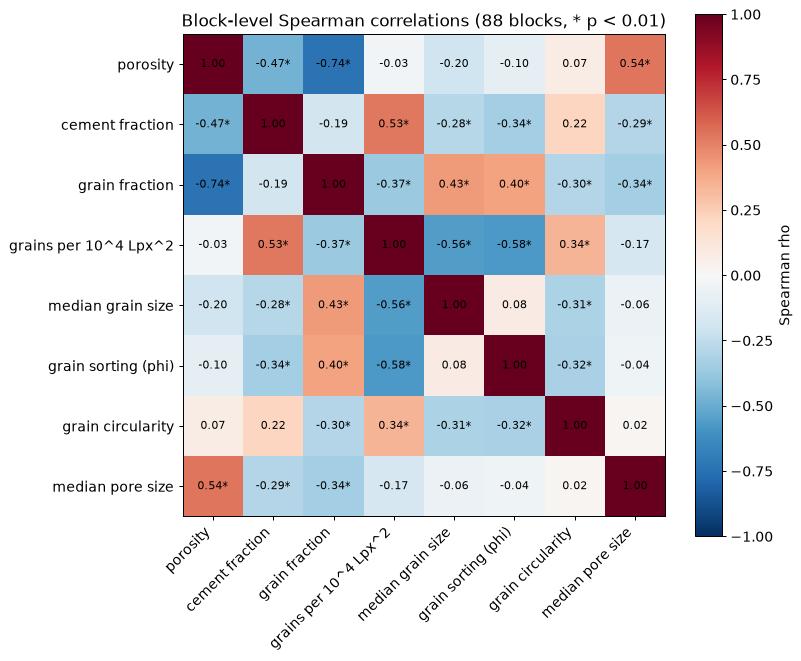

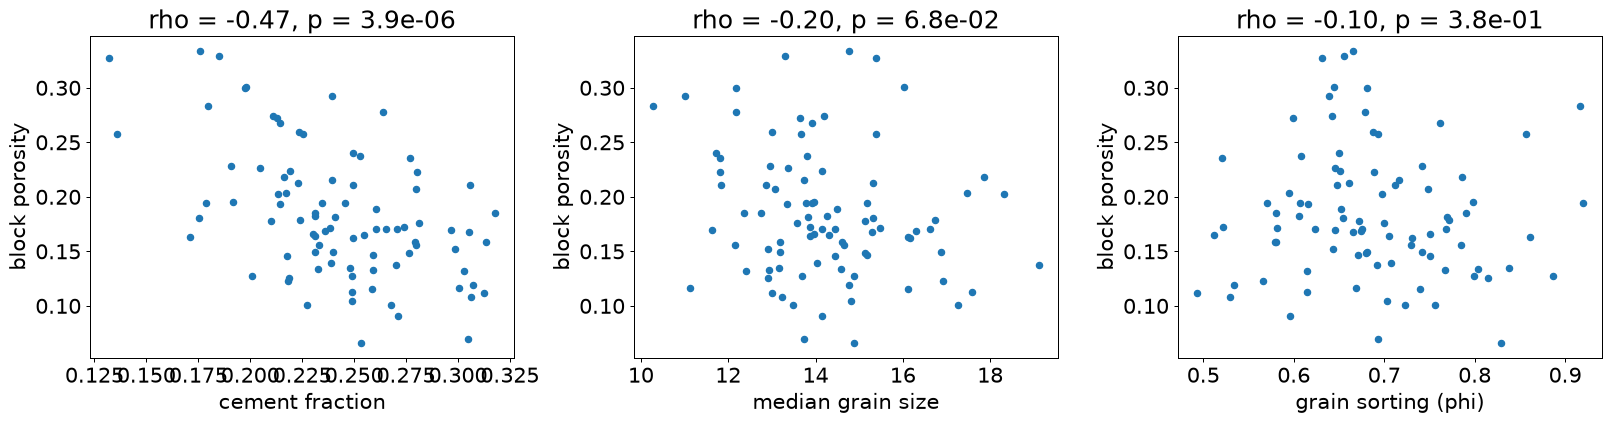

,Spearman rho with porosity,p_value
cement fraction,-0.47,3.9e-06
grain fraction,-0.74,2.4e-16
grains per 10^4 Lpx^2,-0.03,7.8e-01
median grain size,-0.20,6.8e-02
grain sorting (phi),-0.10,3.8e-01
grain circularity,0.07,5.0e-01
median pore size,0.54,7.3e-08


In [9]:
B = 128
rows = []
for by in range(0, H - B + 1, B):
    for bx in range(0, W - B + 1, B):
        sl = (slice(by, by + B), slice(bx, bx + B))
        gb = g[(g.cx >= bx) & (g.cx < bx + B) & (g.cy >= by) & (g.cy < by + B)]
        pb = pores[(pores.cx >= bx) & (pores.cx < bx + B) & (pores.cy >= by) & (pores.cy < by + B)]
        phi_g = -np.log2(gb.eq_diameter_u)
        rows.append({'bx': bx, 'by': by,
                     'porosity': masks['pore'][sl].mean(), 'cement': masks['cement'][sl].mean(),
                     'grain': masks['grain'][sl].mean(), 'grains_per_1e4px': len(gb) / B ** 2 * 1e4,
                     'grain_D50': gb.eq_diameter_u.median(), 'grain_sorting_phi': phi_g.std(),
                     'grain_circularity': gb.circularity.median(), 'pore_D50': pb.eq_diameter_u.median(),
                     'n_pores': len(pb)})
blocks = pd.DataFrame(rows)
vars_ = ['porosity', 'cement', 'grain', 'grains_per_1e4px', 'grain_D50', 'grain_sorting_phi', 'grain_circularity', 'pore_D50']
NICE = {'porosity': 'porosity', 'cement': 'cement fraction', 'grain': 'grain fraction',
        'grains_per_1e4px': 'grains per 10^4 Lpx^2', 'grain_D50': 'median grain size', 'grain_sorting_phi': 'grain sorting (phi)',
        'grain_circularity': 'grain circularity', 'pore_D50': 'median pore size'}   # readable names for plots and table
rho = blocks[vars_].corr(method='spearman')
pval = pd.DataFrame([[stats.spearmanr(blocks[a], blocks[b], nan_policy='omit').pvalue for b in vars_] for a in vars_], index=vars_, columns=vars_)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(rho, cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar(im, label='Spearman rho')
ax.set_xticks(range(len(vars_))); ax.set_xticklabels([NICE[v] for v in vars_], rotation=45, ha='right'); ax.set_yticks(range(len(vars_))); ax.set_yticklabels([NICE[v] for v in vars_])
for i in range(len(vars_)):
    for j in range(len(vars_)):
        ax.text(j, i, f'{rho.iloc[i, j]:.2f}' + ('*' if pval.iloc[i, j] < 0.01 and i != j else ''), ha='center', va='center', fontsize=8)
ax.set_title(f'Block-level Spearman correlations ({len(blocks)} blocks, * p < 0.01)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, x in zip(ax, ['cement', 'grain_D50', 'grain_sorting_phi']):
    a.scatter(blocks[x], blocks.porosity, s=25)
    a.set_xlabel(NICE[x]); a.set_ylabel('block porosity')
    r_ = stats.spearmanr(blocks[x], blocks.porosity); a.set_title(f'rho = {r_.statistic:.2f}, p = {r_.pvalue:.1e}')
plt.tight_layout(); plt.show()
rho['porosity'].drop('porosity').round(2).to_frame('Spearman rho with porosity').assign(p_value=pval['porosity'].drop('porosity').map('{:.1e}'.format)).rename(index=NICE)

**Reading the plots.**
- **Heat map:** each cell is the **Spearman rank correlation rho** between two block variables: +1 (red) = rise together,
  -1 (blue) = one rises as the other falls, 0 = unrelated; * = real effect (p < 0.01). It is panel (d) of the figure above, with the variables of the table.
- **Scatter plots:** each dot is one block, with its porosity (y) against cement, median grain size and sorting (x).
- **Table:** correlation of every variable with porosity. Porosity falls with **cement (rho = -0.47)** and with grain
  fraction (-0.74), and rises with pore size (+0.54). Grain size, sorting and grain shape show **no significant
  relation**. Local porosity is controlled by **cementation (diagenesis), not by the texture** of the grains.

## 8. Save

**What is saved** (in `outputs/`): the REV windows and REV sizes (section 1), integral range (3), correlation functions
and lengths (2), Clark-Evans results (5), block variables and their correlations (7), and the 128 Lpx porosity map
(6), all prefixed `04_`.

In [10]:
pd.concat([d.assign(phase=n) for n, d in rev.items()]).to_csv('../outputs/04_rev_random_windows.csv', index=False)
rev_tab.to_csv('../outputs/04_rev_sizes.csv'); ir_tab.to_csv('../outputs/04_integral_range.csv'); corr_tab.to_csv('../outputs/04_correlation_lengths.csv')
pd.concat([d.assign(phase=n) for n, d in cf.items()]).to_csv('../outputs/04_correlation_functions.csv', index=False)
pd.DataFrame(ce).to_csv('../outputs/04_clark_evans.csv', index=False)
blocks.to_csv('../outputs/04_blocks.csv', index=False); rho.to_csv('../outputs/04_block_spearman.csv')
np.save('../outputs/04_porosity_map_128.npy', por_map)
print('saved')

saved


## Findings

**1. REV (how large a sample must be)**

| Phase | Correlation length (1/e) | Integral range sqrt(A3) | REV, CV = 10 % (measured / theory) | REV, CV = 5 % (theory) |
|---|---|---|---|---|
| Grain | 4.6 Lpx | 13.5 Lpx | 112 / 117 Lpx | 234 Lpx |
| Pore | 6.4 Lpx | 19.0 Lpx | 357 / 399 Lpx | ~ 800 Lpx |
| Cement | 2.8 Lpx | 13.3 Lpx | 240 / 234 Lpx | ~ 470 Lpx |

- **Porosity is the hardest property to represent.** A window must be ~ 360 Lpx (~ 26 median grain diameters) to
  estimate porosity within +-20 % (95 %), and ~ 800 Lpx (~ 58 grain diameters) for +-10 %. Grain fraction stabilises
  about 3x faster.
- Consequence for the data: the **large image** (1482 x 1061 Lpx) is above the porosity REV. The **small image**
  (717 x 477 Lpx, ~ 585 Lpx equivalent square) gives porosity within about +-14 %. Its porosity (19.0 %) agrees with
  the large image (18.6 %), and its CV(L) curve follows the large-image curve (same rock, same statistics).
- The **integral-range theory** (Kanit et al., 2003) predicts the measured REVs within ~ 10 %. The heterogeneity is
  therefore statistically stationary at the thin-section scale.

**2. Scale of the heterogeneity: porous zones of ~ 150-250 Lpx.** Three independent methods agree:
- the apparent integral range A3(L) grows up to L ~ 250 Lpx and then levels off. The CV(L) slope for porosity is
  -0.75, shallower than the -1 of a purely short-range medium;
- **lacunarity** of the real pores exceeds that of randomly relocated (non-overlapping) pore bodies. The excess
  grows with box size and peaks at ~ 2.2x at r ~ 200 Lpx;
- **random labeling test**: the largest 20 % pores are clustered *among pores* at r = 115-195 Lpx (above the
  199-simulation envelope).

  So the pore space is **not** randomly distributed. Large pores group into porous zones ~ 10-15 grain diameters
  across, separated by tighter, more cemented zones. The moving-window map shows local porosity from 3 % to 65 %
  (128 Lpx window); 128 Lpx blocks range from 7 % to 33 %.

**3. Short-range order.** Clark-Evans R > 1 for grains (1.45), pores (1.28) and even large pores (1.12), and Ripley's
L(r) falls below the CSR envelope at r < ~ 40 Lpx. This is the expected **hard-core** effect of a grain-supported
framework: grains cannot overlap, and pores are separated by grains. It is not a depositional signal.

**4. Isotropy.** The 2D autocorrelation is circular and the x/y correlation lengths differ by < 10 %, so there is no
preferred orientation at pore scale. The vertical C(r) tail stays slightly positive (~ 0.01-0.02) to ~ 400 Lpx,
while the horizontal tail oscillates around 0. This is a weak hint of layer-parallel (horizontal) structure.

**5. What controls local porosity (block data mining, 88 blocks of 128 Lpx)?**
- Porosity vs **cement**: rho = -0.47 (p = 4e-6). Porous blocks are those where less intergranular space is
  occluded by cement. This is the main diagenetic control.
- Porosity vs **grain fraction**: rho = -0.74 (p = 2e-16). Looser packing gives more pore space.
- Porosity vs **pore size (D50)**: rho = +0.54. Porous zones have *larger* pores, not just more of them.
- Porosity vs **grain size, sorting and grain shape**: not significant (|rho| <= 0.20, p > 0.05). Within this sample the
  textural variation is too small to control porosity; **cement distribution (diagenesis) dominates over texture**.